# Schritt 1: Explorative Datenanalyse der französischen Kfz-Haftpflichtdaten

**Ziel dieses Notebooks:** die Daten kennenlernen, Probleme identifizieren, die ein Tarifierungsmodell verfälschen oder unbrauchbar machen würden, und die grundlegenden statistischen Zusammenhänge herausarbeiten, die für die anschließende Modellierung wichtig sind.

**Daten:** `freMTPL2freq` (Verträge) und `freMTPL2sev` (Schäden) aus dem R-Paket CASdatasets, Release Januar 2017 (dasselbe Release wie OpenML 41214/41215). Herunterladen mit `python get_data.py`.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)   # show wide tables without cutting columns

## 1. Daten unverändert laden
Zuerst schaue ich mir die Rohdaten *ohne jede Veränderung* an: Größe, Datentypen und die ersten Zeilen. Alles, was mir hier auffällt, prüfe ich in den folgenden Abschnitten genauer.

In [2]:
# load the data (download it first with: python get_data.py)
freq_raw = pd.read_parquet("../data/freMTPL2freq.parquet")
sev_raw = pd.read_parquet("../data/freMTPL2sev.parquet")

print("freMTPL2freq:", freq_raw.shape, "| freMTPL2sev:", sev_raw.shape)
print("\nfreMTPL2freq dtypes:\n" + freq_raw.dtypes.to_string())
print("\nfreMTPL2sev dtypes:\n" + sev_raw.dtypes.to_string())

freq_raw.head()  # the first look at the policies: one row per policy ID

freMTPL2freq: (678013, 12) | freMTPL2sev: (26639, 2)

freMTPL2freq dtypes:
IDpol          float64
ClaimNb        float64
Exposure       float64
Area          category
VehPower         Int32
VehAge           Int32
DrivAge          Int32
BonusMalus       Int32
VehBrand      category
VehGas          string
Density          Int32
Region        category

freMTPL2sev dtypes:
IDpol            Int32
ClaimAmount    float64


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1.0,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3.0,1.0,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5.0,1.0,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10.0,1.0,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11.0,1.0,0.84,B,7,0,46,50,B12,Diesel,76,R72


**Findings**

* The policy table `freMTPL2freq` has 678,013 rows and 12 columns (one row per contract).
  The claims table `freMTPL2sev` has 26,639 rows and 2 columns (one row per claim).
* `IDpol` and `ClaimNb` are stored as `float64`, although by their meaning (an identifier and a count)
  they must be whole numbers. `VehPower`, `VehAge`, `DrivAge`, `BonusMalus` and `Density` are stored
  as integers.
* `Area`, `VehBrand` and `Region` are stored as categories (factors in the R source), `VehGas` as text.

## 2. Datentypen und fehlende Werte

In [3]:
# clean the types and count the missing values
f = freq_raw.copy()
t = sev_raw.copy()

int_cols = ["IDpol", "ClaimNb", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]
print("only whole numbers:", (f[int_cols] % 1 == 0).all().all())

f[int_cols] = f[int_cols].astype("int64")
t["IDpol"] = t["IDpol"].astype("int64")

for col in ["Area", "VehBrand", "VehGas", "Region"]:
    f[col] = f[col].astype(str)              # plain text instead of R factor levels

print(f.isna().sum())

only whole numbers: True


IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64

**Findings**

* The seven whole-number columns contain only whole numbers and are cast to `int64`. The four text
  columns are converted to plain text.
* No column has missing values.

## 3. Schlüssel und Schäden ohne Vertrag

In [4]:
# keys, and claims without a policy
print("IDpol unique in the policy table:", f["IDpol"].is_unique, "| rows with a repeated ID in the policy table =", len(f) - f["IDpol"].nunique())
print("IDpol unique in the claim table:", t["IDpol"].is_unique, "| rows with a repeated ID in the claim table =", len(t)-t["IDpol"].nunique())

orphan = ~t["IDpol"].isin(f["IDpol"])        # does every claim belong to a contract?
print("claim rows without a contract:", orphan.sum())
print("number of IDs without a contract:", t.loc[orphan, "IDpol"].nunique())
print("their share of the total claim amount:",
       round(t.loc[orphan, "ClaimAmount"].sum() / t["ClaimAmount"].sum(), 4))

t = t[~orphan]                               # drop them: no features, no exposure

IDpol unique in the policy table: True | rows with a repeated ID in the policy table = 0
IDpol unique in the claim table: False | rows with a repeated ID in the claim table = 1689
claim rows without a contract: 195
number of IDs without a contract: 6
their share of the total claim amount: 0.013


**Findings**

* `IDpol` is unique in the policy table (678,013 rows, no repeated ID). The claims table can have
  several rows per contract (1,689 rows with a repeated ID), so the claims are first aggregated per
  `IDpol` and then left-joined to the policy table (next section).
* **195 claim rows belong to only 6 policy IDs that do not exist in the policy table.** That is about
  33 claim rows per ID, which is implausible for a private motor contract. Without risk features and
  exposure they cannot be used for pricing → **dropped**. They hold 1.3 % of the total claim amount.

## 4. Schäden pro Vertrag zusammenfassen und mit den Verträgen verknüpfen

In [5]:
#Make one row per contract in the reduced claim table and then join with the policy table
claims = t.groupby("IDpol")["ClaimAmount"].agg(["count", "sum"]).reset_index()
claims.columns = ["IDpol", "claim_rows", "ClaimAmount"]

df = f.merge(claims, on="IDpol", how="left")
df["claim_rows"] = df["claim_rows"].fillna(0).astype(int)
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)

assert len(df) == len(f)                                             # no contract lost or doubled
assert np.isclose(df["ClaimAmount"].sum(), t["ClaimAmount"].sum())   # no claim amount lost

pd.crosstab(df["ClaimNb"], df["claim_rows"])

claim_rows,0,1,2,3,4,5,6,8,9,11,16
ClaimNb,,,,,,,,,,,
0,643953,0,0,0,0,0,0,0,0,0,0
1,8608,23570,0,0,0,0,0,0,0,0,0
2,485,1,1298,0,0,0,0,0,0,0,0
3,20,0,0,62,0,0,0,0,0,0,0
4,2,0,0,0,5,0,0,0,0,0,0
5,0,0,0,0,0,2,0,0,0,0,0
6,0,0,0,0,0,0,1,0,0,0,0
8,0,0,0,0,0,0,0,1,0,0,0
9,0,0,0,0,0,0,0,0,1,0,0


**Findings**

The table compares the declared number of claims (`ClaimNb`, rows) with the number of claims that
have an amount (`claim_rows`, columns).

* **Diagonal:** 24,943 contracts declare exactly as many claims as they have amounts. Together with the
  one contract that declares 2 claims and has 1 amount, 24,944 contracts have at least one claim amount.
* **Column 0:** 9,116 contracts declare at least one claim but have no amount at all.
* **Upper triangle is empty:** no contract has more amounts than declared claims.

So `ClaimNb` and the claim amounts agree for almost all contracts, except for a group of contracts
with declared claims and no amount. The next cell shows where these contracts are.

## 5. Der ID-Block mit fehlenden Schadenhöhen

In [6]:
# where are the contracts that declare a claim but have no claim amount?
df["no_amount"] = (df["ClaimNb"] > 0) & (df["claim_rows"] == 0)
print("contracts with a declared claim but no amount:", df["no_amount"].sum())
print(df.loc[df["no_amount"], "IDpol"].quantile([0.1, 0.5, 0.9, 0.99]))

print("largest IDpol in the portfolio:", df["IDpol"].max())
print("share of all contracts with IDpol <= 25000:", round((df["IDpol"] <= 25000).mean(), 3))

contracts with a declared claim but no amount: 9116
0.10     1944.5
0.50    10292.5
0.90    23158.5
0.99    24817.7
Name: IDpol, dtype: float64
largest IDpol in the portfolio: 6114330
share of all contracts with IDpol <= 25000: 0.014


**Findings**

9,116 contracts declare at least one claim (`ClaimNb` > 0) but have no claim amount. 99 % of them have
an `IDpol` below 24,818, although IDs go up to 6.1 million and IDs up to 25,000 make up only 1.4 % of
all contracts. These contracts are concentrated in one ID block, so this looks like a data problem,
not like randomly missing amounts. The next cell compares this block with the rest of the portfolio.

In [7]:
# the ID block with missing claim amounts against the rest
df["block"] = df["IDpol"] <= 25000
df["declares_claim"] = df["ClaimNb"] > 0

g = df.groupby("block").agg(policies=("IDpol", "size"),
                            exposure=("Exposure", "sum"),
                            share_declaring=("declares_claim", "mean"),
                            declared=("ClaimNb", "sum"),
                            with_amount=("claim_rows", "sum"))
g["freq_declared"] = g["declared"] / g["exposure"]
g["freq_with_amount"] = g["with_amount"] / g["exposure"]
print(g.round(3))

       policies    exposure  share_declaring  declared  with_amount  freq_declared  freq_with_amount
block                                                                                               
False    668600  353680.263            0.037     26158        26135          0.074             0.074
True       9413    4819.183            0.997      9944          309          2.063             0.064


In [8]:
# what would the declared count do to a risk feature? claim frequency by vehicle age, declared against with an amount
veh_age = pd.cut(df["VehAge"], [-1, 0, 1, 4, 9, 14, 200], labels=["0", "1", "2-4", "5-9", "10-14", "15+"])
g = df.groupby(veh_age, observed=True)[["Exposure", "ClaimNb", "claim_rows"]].sum()
g["freq_declared"] = g["ClaimNb"] / g["Exposure"]
g["freq_with_amount"] = g["claim_rows"] / g["Exposure"]
g["declared/with_amount"] = g["freq_declared"] / g["freq_with_amount"]
print(g.round(3))
print("share of new vehicles (VehAge 0): block", round((df.loc[df["block"], "VehAge"] == 0).mean(), 3),
      "| rest", round((df.loc[~df["block"], "VehAge"] == 0).mean(), 3))

# decision: from here on, the claim count is claim_rows (claims that have an amount).
# ClaimNb stays unchanged and is not used after this cell.

          Exposure  ClaimNb  claim_rows  freq_declared  freq_with_amount  declared/with_amount
VehAge                                                                                        
0        16719.029     5205        1181          0.311             0.071                 4.407
1        32749.538     2931        2328          0.089             0.071                 1.259
2-4      79548.848     7370        5904          0.093             0.074                 1.248
5-9     100255.438     9914        8044          0.099             0.080                 1.232
10-14    86098.454     7764        6495          0.090             0.075                 1.195
15+      43128.140     2918        2492          0.068             0.058                 1.171
share of new vehicles (VehAge 0): block 0.412 | rest 0.081


**Findings**

In the block (`IDpol` ≤ 25,000; 9,413 contracts, 1.4 % of the portfolio), 99.7 % of the contracts
declare a claim, against 3.7 % in the rest. The declared frequency is 2.06 claims per year, about
28 times the 0.074 of the rest, which is not plausible. Only 309 of the 9,944 declared claims in the
block have an amount. Counted with amounts, the block's frequency is 0.064, in the same range as the
rest.

The block is not a random sample: 41 % of its contracts have a brand-new vehicle (`VehAge` 0), against 8 % in
the rest. With the declared count, new vehicles would look 4.4 times as risky as they are (frequency 0.311
instead of 0.071); for all other vehicle ages the declared count is 17–26 % higher. So the declared count
would not only raise the premium level but also distort the relative price of a whole group.

**Decision:** the claim count is the number of claims with an amount (`claim_rows`). `ClaimNb` is not
used further.

## 6. Kraftstofftyp

In [9]:
# the fuel type: levels and missing values
print(df["VehGas"].value_counts(dropna=False))

VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64


**Findings**

`VehGas` has two levels, Regular (345,877 contracts) and Diesel (332,136), and no missing values. It is
used as a category; its relation to the claims is shown in section 11.

## 7. Exposure

count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64
Exposure > 1: 1224


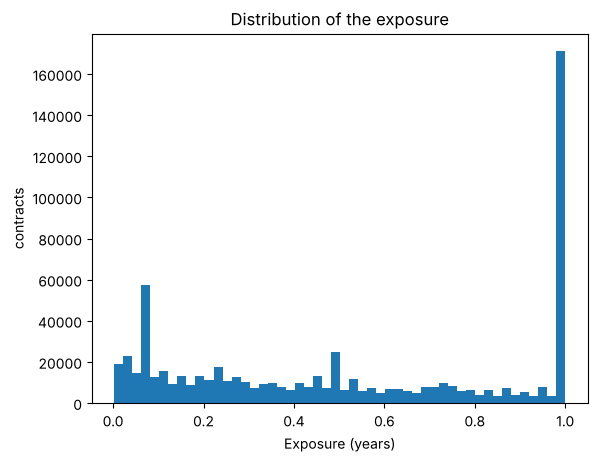

In [10]:
#Exposure
print(df["Exposure"].describe())
print("Exposure > 1:", (df["Exposure"] > 1).sum())

df["Exposure"] = df["Exposure"].clip(upper=1)      # the period is one year

plt.hist(df["Exposure"], bins=50)
plt.xlabel("Exposure (years)")
plt.ylabel("contracts")
plt.title("Distribution of the exposure")
plt.show()

**Findings**

Exposure ranges from 1 day to 2.01 years. Half of the contracts are observed for less than half a year
(median 0.49). **1,224 contracts have an exposure above 1**, which is not possible within one year of
observation → **capped at 1.0**.

## 8. Alter des Fahrers und weitere numerische Merkmale

In [11]:
# driver age and the other numeric risk features, for plausibility
print(df[["DrivAge", "VehPower", "VehAge", "BonusMalus", "Density"]].describe().round(1))

old_car = df["VehAge"] >= 99
print("contracts with VehAge 99 or 100:", old_car.sum(),
      "| contract-years:", round(df.loc[old_car, "Exposure"].sum(), 1),
      "| claims:", df.loc[old_car, "claim_rows"].sum())

        DrivAge  VehPower    VehAge  BonusMalus   Density
count  678013.0  678013.0  678013.0    678013.0  678013.0
mean       45.5       6.5       7.0        59.8    1792.4
std        14.1       2.1       5.7        15.6    3958.6
min        18.0       4.0       0.0        50.0       1.0
25%        34.0       5.0       2.0        50.0      92.0
50%        44.0       6.0       6.0        50.0     393.0
75%        55.0       7.0      11.0        64.0    1658.0
max       100.0      15.0     100.0       230.0   27000.0
contracts with VehAge 99 or 100: 48 | contract-years: 27.9 | claims: 1


**Findings**

* Driver ages range from 18 to 100 (median 44). All values are plausible, so no cleaning is needed.
* `VehPower` (4–15), `BonusMalus` (50–230) and `Density` (1–27,000) are plausible. `VehAge` has
  48 contracts with 99 or 100 years, which look like placeholder values. With 28 contract-years and
  one claim they cannot influence the results, so they are left as they are.

## 9. Schadenhöhen

count      26444
mean        2266
std        29371
min            1
25%          686
50%         1172
75%         1212
max      4075401
Name: ClaimAmount, dtype: int64
ClaimAmount
1204.00    4792
1128.12    3056
1172.00    2071
1128.00     831
602.00      433
Name: count, dtype: int64
largest claim, share of total cost: 0.068
claims of at least 50,000: 90 | share of total cost: 0.301


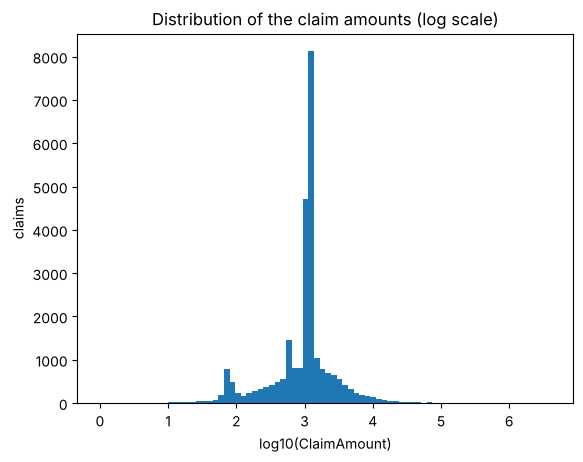

In [12]:
#Claim Amount
ca = t["ClaimAmount"]
print(ca.describe().round().astype(int))
print(ca.value_counts().head(5))                   # the most frequent amounts

print("largest claim, share of total cost:", round(ca.max() / ca.sum(), 3))
big = ca >= 50000
print("claims of at least 50,000:", big.sum(),
      "| share of total cost:", round(ca[big].sum() / ca.sum(), 3))

plt.hist(np.log10(ca), bins=80)
plt.xlabel("log10(ClaimAmount)")
plt.ylabel("claims")
plt.title("Distribution of the claim amounts (log scale)")
plt.show()

**Findings**

* The five most common amounts cover 11,183 claims, 42 % of all claims. These look like fixed
  flat-rate amounts. They explain why the 75 % quantile (1,212) is so close to the median (1,172),
  and they cause the tall spike in the histogram.
* The tail is heavy: 90 claims of at least 50,000 (0.3 % of the claims) make up 30 % of the total
  claim amount, and the largest single claim (4.08 million) alone is 6.8 %.

## 10. Zielgröße und Bestandskennzahlen

In [13]:
#Target and Portfolio figures
df["PurePremium"] = df["ClaimAmount"] / df["Exposure"]      # the dependent variable

E = df["Exposure"].sum()
N = df["claim_rows"].sum()
S = df["ClaimAmount"].sum()
print("frequency:", round(N / E, 4), "| severity:", round(S / N, 2), "| pure premium:", round(S / E, 2))
print("share of contracts with target 0:", round((df["ClaimAmount"] == 0).mean(), 4))
print("unweighted mean of the target:", round(df["PurePremium"].mean(), 2))
print("exposure-weighted mean of the target:", round(np.average(df["PurePremium"], weights=df["Exposure"]), 2))
print(df.nlargest(3, "PurePremium")[["IDpol", "Exposure", "ClaimAmount", "PurePremium"]])

frequency: 0.0738 | severity: 2265.51 | pure premium: 167.18
share of contracts with target 0: 0.9632
unweighted mean of the target: 383.27
exposure-weighted mean of the target: 167.18
          IDpol  Exposure  ClaimAmount  PurePremium
150027  1120377      0.22   4075400.56   18524548.0
25274     53865      0.01    183073.66   18307366.0
399662  3083780      0.02    182050.00    9102500.0


**Findings**

* Portfolio: 0.0738 claims per contract-year, 2,266 per claim, **pure premium 167.18 per contract-year**.
* 96.3 % of the contracts have target 0. The target is extremely skewed.
* The unweighted mean of the target (383) is more than twice the pure premium, because very short
  contracts with a claim get extreme values (0.01 years with a claim amount of 183,000 gives 18.3 million).
  Weighted by exposure, the mean is exactly the pure premium. **So every average and the model must
  be weighted by exposure.**

## 11. Einflussfaktoren (eindimensionale Analyse)

                  Exposure  claim_rows  ClaimAmount  frequency  severity  pure_premium
BonusMalusBand                                                                        
(49, 50]        225152.651       11592  22282394.02      0.051  1922.222        98.966
(50, 60]         47958.467        3576   7025420.41      0.075  1964.603       146.490
(60, 70]         26484.083        3116   6091205.46      0.118  1954.816       229.995
(70, 80]         26555.703        2798   6142659.22      0.105  2195.375       231.312
(80, 90]         15243.429        1720   3657454.13      0.113  2126.427       239.936
(90, 100]        13395.042        2386  12150153.70      0.178  5092.269       907.063
(100, 300]        3570.729        1256   2559929.56      0.352  2038.160       716.921


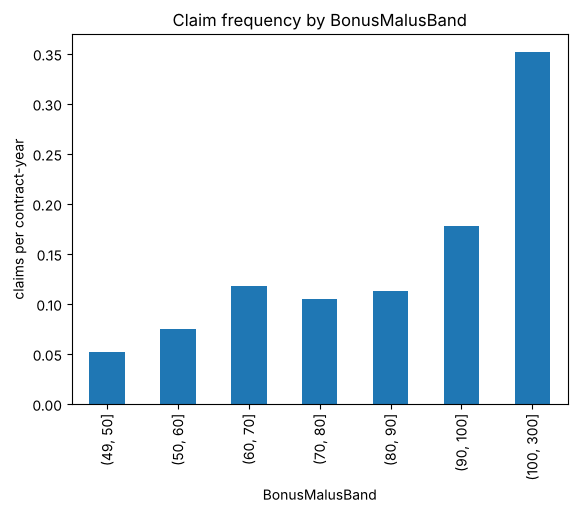

              Exposure  claim_rows  ClaimAmount  frequency   severity  pure_premium
DrivAgeBand                                                                        
(17, 20]      2584.543         617   8287047.97      0.239  13431.196      3206.388
(20, 24]      9904.348        1394   3454296.24      0.141   2477.974       348.766
(24, 29]     25775.651        2245   4606636.81      0.087   2051.954       178.720
(29, 39]     82320.268        5725  11324214.63      0.070   1978.029       137.563
(39, 49]     87645.366        6566  12291965.06      0.075   1872.063       140.247
(49, 59]     79880.858        5623  10483079.87      0.070   1864.322       131.234
(59, 69]     40077.472        2470   4567690.87      0.062   1849.268       113.972
(69, 120]    30171.599        1804   4894285.05      0.060   2713.018       162.215


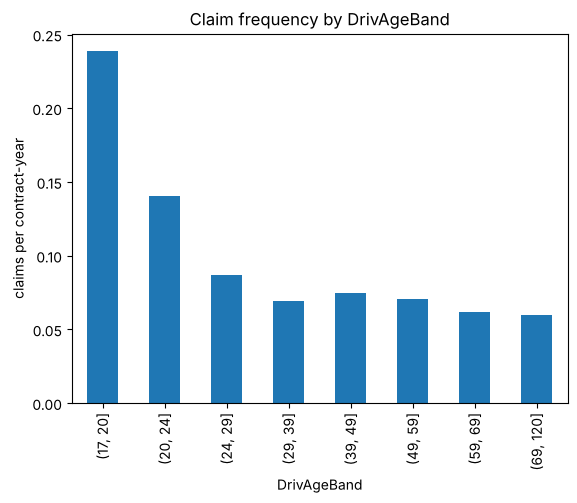

        Exposure  claim_rows  ClaimAmount  frequency  severity  pure_premium
Area                                                                        
A      61956.828        3364   7739630.67      0.054  2300.723       124.920
B      43001.824        2633   8873979.52      0.061  3370.292       206.363
C     104402.524        7093  14612072.43      0.068  2060.069       139.959
D      77087.802        6458  14486501.16      0.084  2243.187       187.922
E      63785.694        6122  13017426.30      0.096  2126.336       204.081
F       8125.434         774   1179606.42      0.095  1524.039       145.175


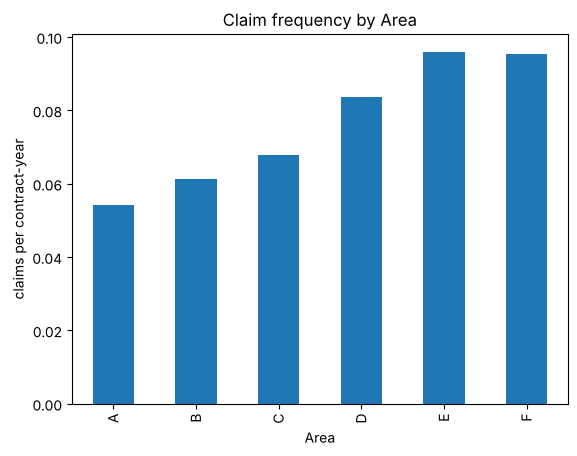

           Exposure  claim_rows  ClaimAmount  frequency  severity  pure_premium
VehGas                                                                         
Diesel   170587.553       13450  27594673.95      0.079  2051.649       161.763
Regular  187772.552       12994  32314542.55      0.069  2486.882       172.094


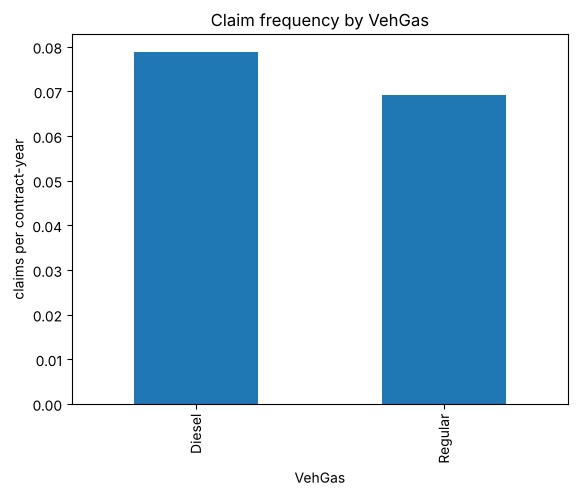

In [14]:
# which features matter?
def oneway(col):
    g = df.groupby(col, observed=True)[["Exposure", "claim_rows", "ClaimAmount"]].sum()
    g["frequency"] = g["claim_rows"] / g["Exposure"]
    g["severity"] = g["ClaimAmount"] / g["claim_rows"]
    g["pure_premium"] = g["ClaimAmount"] / g["Exposure"]
    return g

df["DrivAgeBand"] = pd.cut(df["DrivAge"], [17, 20, 24, 29, 39, 49, 59, 69, 120])
df["BonusMalusBand"] = pd.cut(df["BonusMalus"], [49, 50, 60, 70, 80, 90, 100, 300])

for col in ["BonusMalusBand", "DrivAgeBand", "Area", "VehGas"]:
    g = oneway(col)
    print(g.round(3))
    g["frequency"].plot(kind="bar", title="Claim frequency by " + col)
    plt.ylabel("claims per contract-year")
    plt.show()

In [15]:
# the three largest claims: in which Bonus-Malus band and age group are they?
print(df.nlargest(3, "ClaimAmount")[["IDpol", "ClaimAmount", "claim_rows", "DrivAge", "BonusMalus", "BonusMalusBand", "Area"]])

          IDpol  ClaimAmount  claim_rows  DrivAge  BonusMalus BonusMalusBand Area
150027  1120377   4075400.56           1       19         100      (90, 100]    B
54317    110846   1404185.52           2       20         100      (90, 100]    C
270621  2141337   1301172.60           1       18         100      (90, 100]    D


**Findings**

* **BonusMalus** is the strongest frequency driver: from 0.051 at the best level (50, which holds
  63 % of the exposure) to 0.352 above 100. Severity stays at about 2,000 in all bands except
  (90, 100], which contains the single largest claim (4.08 million). That one claim also makes this
  band's pure premium (907) higher than the worst band (717).
* **Driver age:** the frequency falls from 0.239 for drivers of 18–20 to 0.06–0.075 from age 30 on.
  The severity of 13,431 in the youngest band is again caused by the 4.08 million claim (a 19-year-old
  driver); without it, it is about 6,800, still the highest band.
* **Area:** the frequency rises from A (0.054, rural) to E (0.096, urban); F is close to E (0.095). Severity does
  not follow a pattern; the 3,370 in B is again the 4.08 million claim.
* **VehGas:** Diesel has a slightly higher frequency than Regular (0.079 vs 0.069) but a lower
  severity (2,052 vs 2,487), so the pure premiums are close (162 vs 172).

**Conclusions for the model:** the risk features act mainly on the claim frequency; severity is
roughly constant except for single large claims. Large claims must be capped (or modelled separately)
so that one claim does not distort the premium of a whole group. Part of the age effect overlaps with
BonusMalus (next section), which only a multivariate model can separate.

## 12. Zusammenhänge zwischen den Merkmalen

In [16]:
# Relationship between features
print(df.groupby("Area")["Density"].agg(["min", "max"]))
print(df[["DrivAge", "BonusMalus", "VehAge", "VehPower", "Density"]].corr(method="spearman").round(2))

        min    max
Area              
A         1     50
B        50    100
C       100    500
D       500   1993
E      2001   9850
F     10008  27000


            DrivAge  BonusMalus  VehAge  VehPower  Density
DrivAge        1.00       -0.57   -0.08      0.04    -0.04
BonusMalus    -0.57        1.00    0.08     -0.07     0.14
VehAge        -0.08        0.08    1.00     -0.00    -0.10
VehPower       0.04       -0.07   -0.00      1.00    -0.01
Density       -0.04        0.14   -0.10     -0.01     1.00


**Findings**

* `Area` is a banding of `Density`: each area covers its own density range, and only the boundary
  values 50, 100 and 500 appear in two areas. So `Area` adds almost nothing beyond `Density`, and the
  model should use one of the two.
* Among the numeric features, the only strong correlation is `DrivAge`–`BonusMalus` (−0.57): young
  drivers have not yet had time to earn a low bonus-malus. All other correlations are |ρ| ≤ 0.14.

## 13. Zusammenfassung

**Data problems found and decisions taken**

| Problem | Size | Decision |
|---|---|---|
| Claim rows whose `IDpol` is not in the policy table | 195 rows, 6 IDs, 1.3 % of the claim amount | dropped: no features, no exposure |
| Contracts with declared claims (`ClaimNb` > 0) but no claim amount | 9,116 contracts, almost all with `IDpol` $\le$ 25,000; with the declared count, new vehicles would look 4.4 times as risky | claim count = number of claims with an amount; `ClaimNb` not used |
| Exposure above one year | 1,224 contracts, up to 2.01 | capped at 1.0 |
| Whole-number columns stored as `float64` or `Int32`; `Area`, `VehBrand`, `Region` as categories, `VehGas` as string | 7 columns, 4 columns | cast to `int64`, converted to text |

**Portfolio:** 678,013 contracts, 358,360 contract-years, 26,444 claims, 59.9 million total claim
amount. Frequency 0.0738, severity 2,266, **pure premium 167.18 per contract-year**. 96.3 % of the
contracts have no claim.

**Relationships that matter for the model**

* The risk features act mainly on the claim **frequency**: `BonusMalus` (0.05 → 0.35), driver age
  (young drivers 0.24 vs 0.06–0.075), `Area`/`Density` (rural A 0.054 → urban E 0.096), `VehGas` (small).
* **Severity** is roughly constant at about 2,000, except for single large claims: 90 claims of at
  least 50,000 hold 30 % of the total claim amount, the largest one alone 6.8 %.
* `Area` is a banding of `Density`; `DrivAge` and `BonusMalus` are correlated (−0.57).

**Consequences for the modelling step**

1. Model the target per contract-year and **weight by exposure**.
2. **Cap large claims** before fitting (or model frequency and severity separately), so that single
   claims do not distort the premium of whole groups.
3. Use `Density` or `Area`, not both; let the model separate the age and bonus-malus effects.
4. Evaluate with a metric that fits a zero-heavy, skewed target (e.g. Poisson/Tweedie deviance),
   plus calibration checks per risk group.